In [1]:
from pathlib import Path
from torchvision.datasets import OxfordIIITPet

DATA =  Path.cwd().parent / 'data'
print("data folder:", DATA.resolve())

OxfordIIITPet(root=DATA, download=True)

PET = DATA / "oxford-iiit-pet"
print(list(PET.iterdir()))


data folder: /Users/nestordzadzamia/Projects/upgaming/data
[PosixPath('/Users/nestordzadzamia/Projects/upgaming/data/oxford-iiit-pet/images'), PosixPath('/Users/nestordzadzamia/Projects/upgaming/data/oxford-iiit-pet/annotations')]


In [2]:
import pandas as pd

ANNOTATIONS = PET / "annotations"
cols = ["image", "class_id", "species", "breed_id"]

def load_split(filename):
    df = pd.read_csv(ANNOTATIONS / filename, sep=" ", header=None, names=cols)
    df["label"] = df["species"] - 1 # 0-cat 1-dog
    df["breed"] = df["image"].str.rsplit("_", n=1).str[0]
    df["path"] = df["image"].apply(lambda name: PET / "images" / f"{name}.jpg")
    return df

df_train_validation = load_split("trainval.txt")
df_test = load_split("test.txt")

print(len(df_train_validation), len(df_test))
print("Shared photos:", len(set(df_train_validation["image"]) & set(df_test["image"])))
df_train_validation.head()

3680 3669
Shared photos: 0


,image,class_id,species,breed_id,label,breed,path
0,Abyssinian_100,1,1,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
1,Abyssinian_101,1,1,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
2,Abyssinian_102,1,1,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
3,Abyssinian_103,1,1,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...
4,Abyssinian_104,1,1,1,0,Abyssinian,/Users/nestordzadzamia/Projects/upgaming/data/...


# Cats vs Dogs (Distribution)

cat    1188
dog    2492
Name: count, dtype: int64
always guessing 'dog' would score: 67.72%
always guessing 'cat' would score: 32.28%


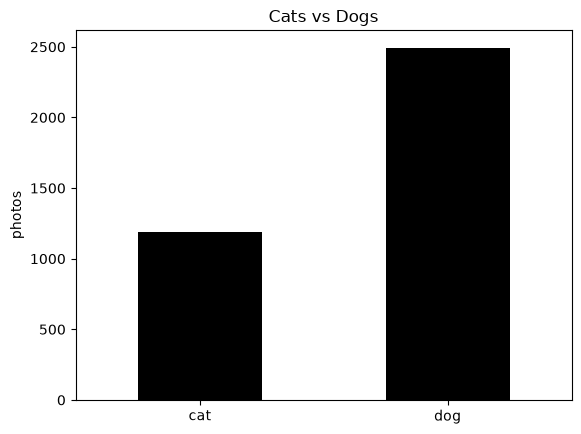

In [3]:
import matplotlib.pyplot as plt

counts = df_train_validation["label"].value_counts().sort_index()
counts.index = ["cat", "dog"]

print(counts)

dog_percentage = counts['dog'] / counts.sum()
cat_percentage = 1 - dog_percentage

print(f"always guessing 'dog' would score: {dog_percentage * 100:.2f}%")
print(f"always guessing 'cat' would score: {cat_percentage * 100:.2f}%")

counts.plot.bar(title="Cats vs Dogs", color="black", rot=0)
plt.ylabel("photos")
plt.show()


# Photos Per Breed

min      93.000000
max     100.000000
mean     99.459459
Name: photos, dtype: float64
label
1    25
0    12
Name: count, dtype: int64


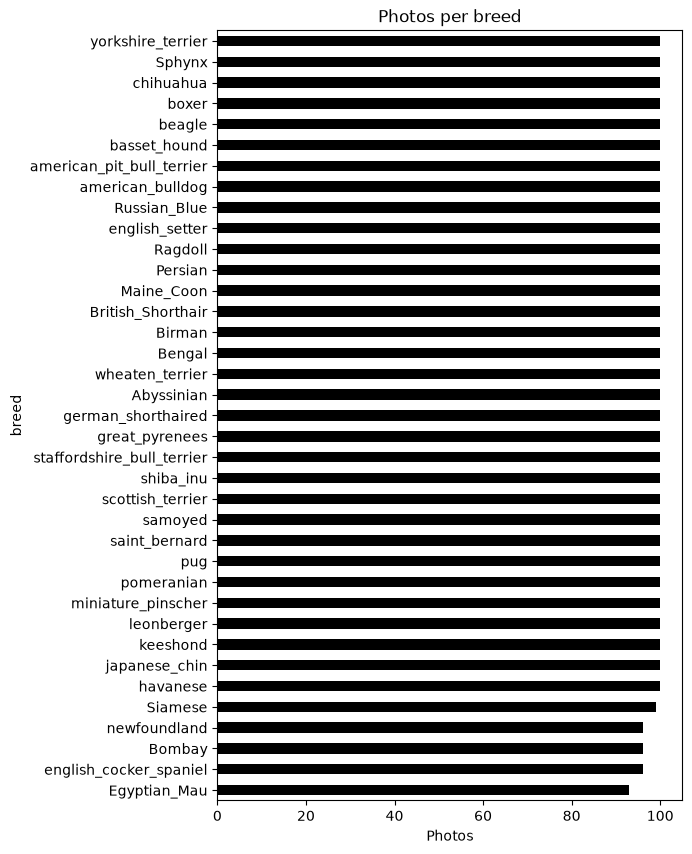

In [4]:
per_breed = df_train_validation.groupby("breed").agg(photos=("image", "size"), label=("label", "first")).sort_values("photos")

per_breed["photos"].plot.barh(figsize=(6, 10), color="black",
                              title="Photos per breed")


print(per_breed["photos"].describe()[["min", "max", "mean"]])
print(per_breed["label"].value_counts())

plt.xlabel("Photos")
plt.show()

# Image sizes

        width  height
count  3680.0  3680.0
mean    431.0   383.0
std     126.0   117.0
min     114.0   108.0
25%     333.0   333.0
50%     500.0   375.0
75%     500.0   500.0
max    3264.0  2606.0


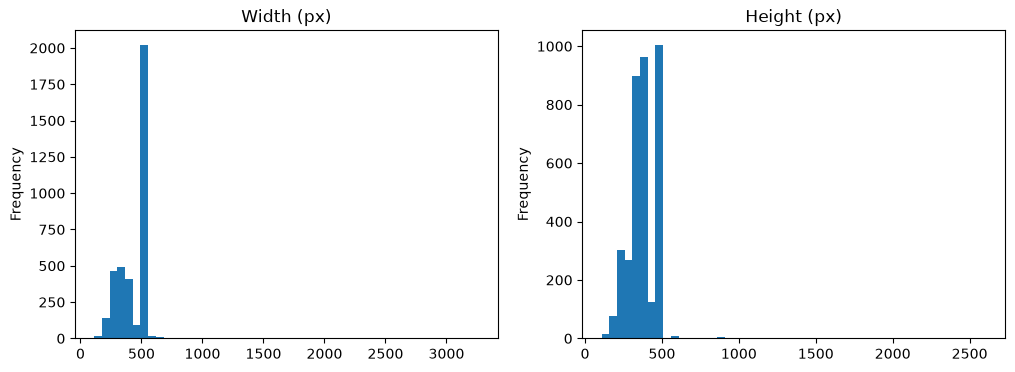

mode
RGB     3678
RGBA       2
Name: count, dtype: int64


In [5]:
from PIL import Image

def image_info(path):
    with Image.open(path) as img:
        return img.width, img.height, img.mode

info = df_train_validation["path"].apply(image_info)
df_train_validation[["width", "height", "mode"]] = pd.DataFrame(info.tolist(), index=df_train_validation.index)

print(df_train_validation[["width", "height"]].describe().round())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_train_validation["width"].plot.hist(bins=50, ax=axes[0], title="Width (px)")
df_train_validation["height"].plot.hist(bins=50, ax=axes[1], title="Height (px)")
plt.show()

print(df_train_validation["mode"].value_counts())

# Takeaways from EDA / Findings

- 3,680 trainval and 3,669 test photos, with no overlap.
- imbalanced: 1,188 cats (32%) vs 2,492 dogs (68%). Always guessing "dog" already scores 67.7%,
  so accuracy alone is misleading, will need F1 and a confusion matrix.
- breeds are balanced (93–100 photos each). The imbalance comes from 12 cat breeds vs 25 dog breeds.
- image sizes vary a lot (from 110 px up to 3,000 px), resize everything to one fixed size, 128×128.
- 2 images are RGBA (4 channels), convert every image to RGB when loading.